In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("../data/diabetes.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Dataset structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Pregnancies,0,0.0
Glucose,0,0.0
BloodPressure,0,0.0
SkinThickness,0,0.0
Insulin,0,0.0
BMI,0,0.0
DiabetesPedigreeFunction,0,0.0
Age,0,0.0
Outcome,0,0.0


Outcome
0    500
1    268
Name: count, dtype: int64

Percentage distribution:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


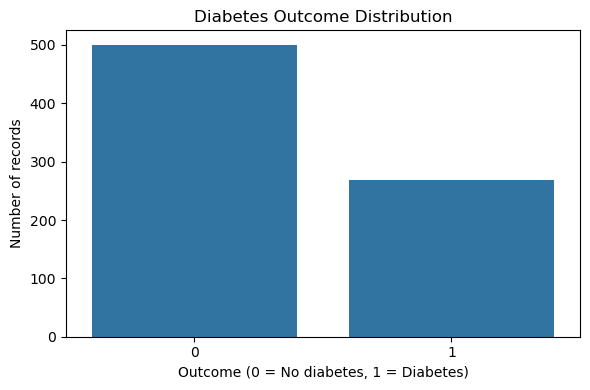

In [6]:
print(df["Outcome"].value_counts())

print("\nPercentage distribution:")
print((df["Outcome"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

In [7]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_summary = pd.DataFrame({
    "Zero_Count": (df[zero_columns] == 0).sum(),
    "Zero_Percentage": (
        (df[zero_columns] == 0).mean() * 100
    ).round(2)
})

display(zero_summary)

,Zero_Count,Zero_Percentage
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


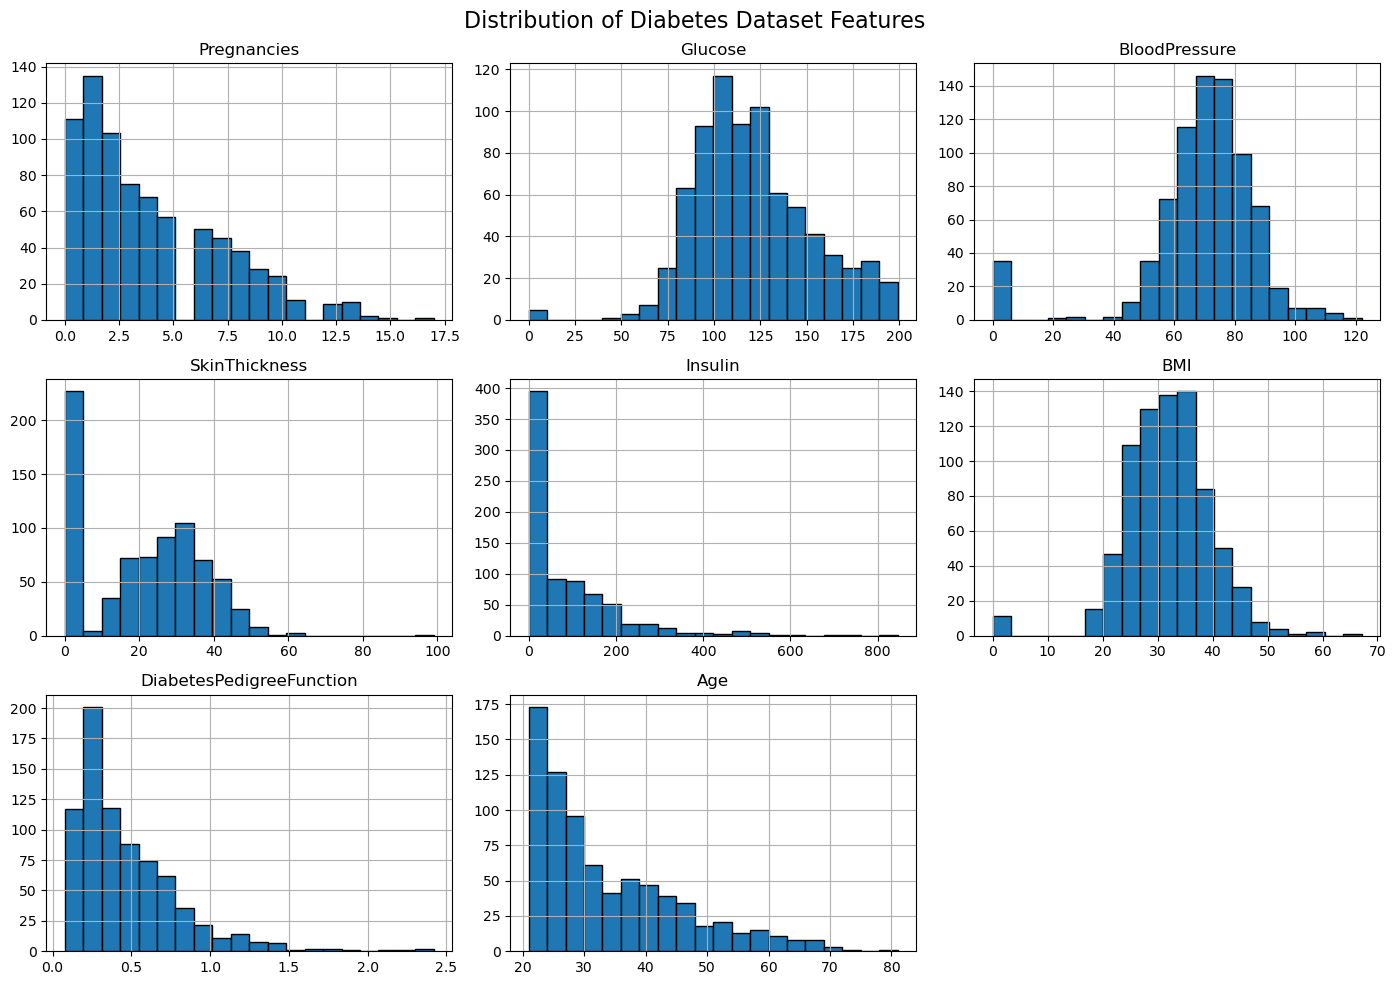

In [8]:
# Distribution of all input features
features = df.drop(columns="Outcome").columns

df[features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Diabetes Dataset Features", fontsize=16)
plt.tight_layout()
plt.savefig("../reports/figures/feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

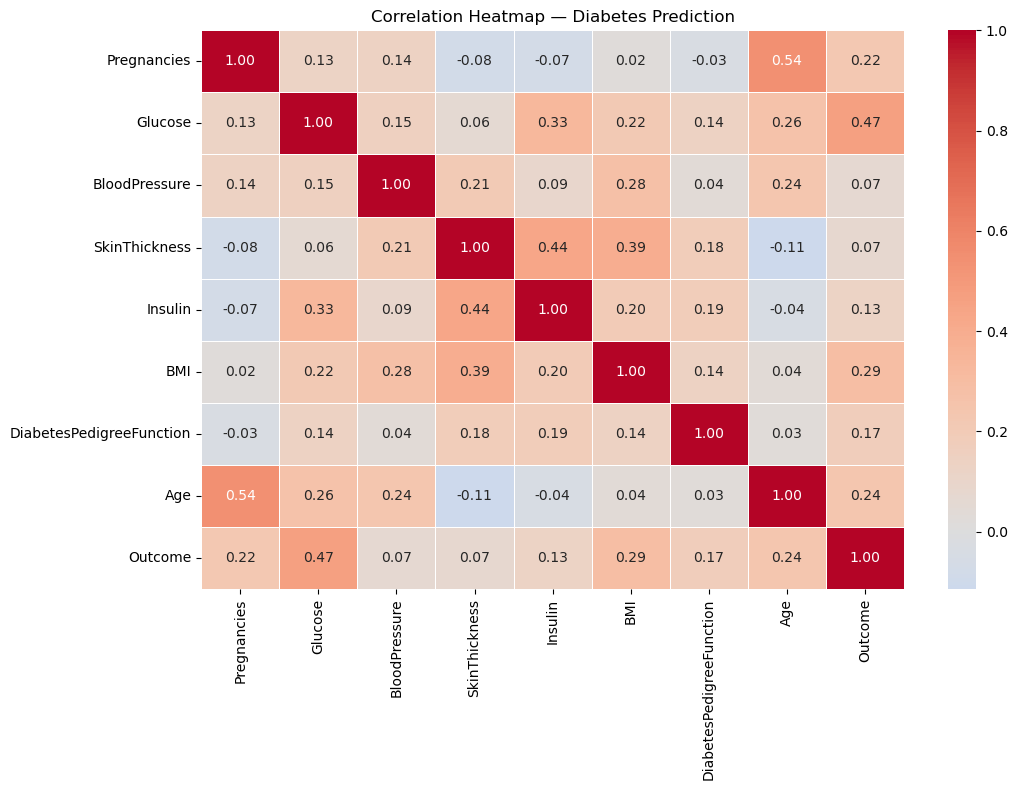

In [9]:

# Calculate correlations between numeric columns
correlation_matrix = df.corr(numeric_only=True)

# Plot the correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Diabetes Prediction")
plt.tight_layout()

plt.savefig(
    "../reports/figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


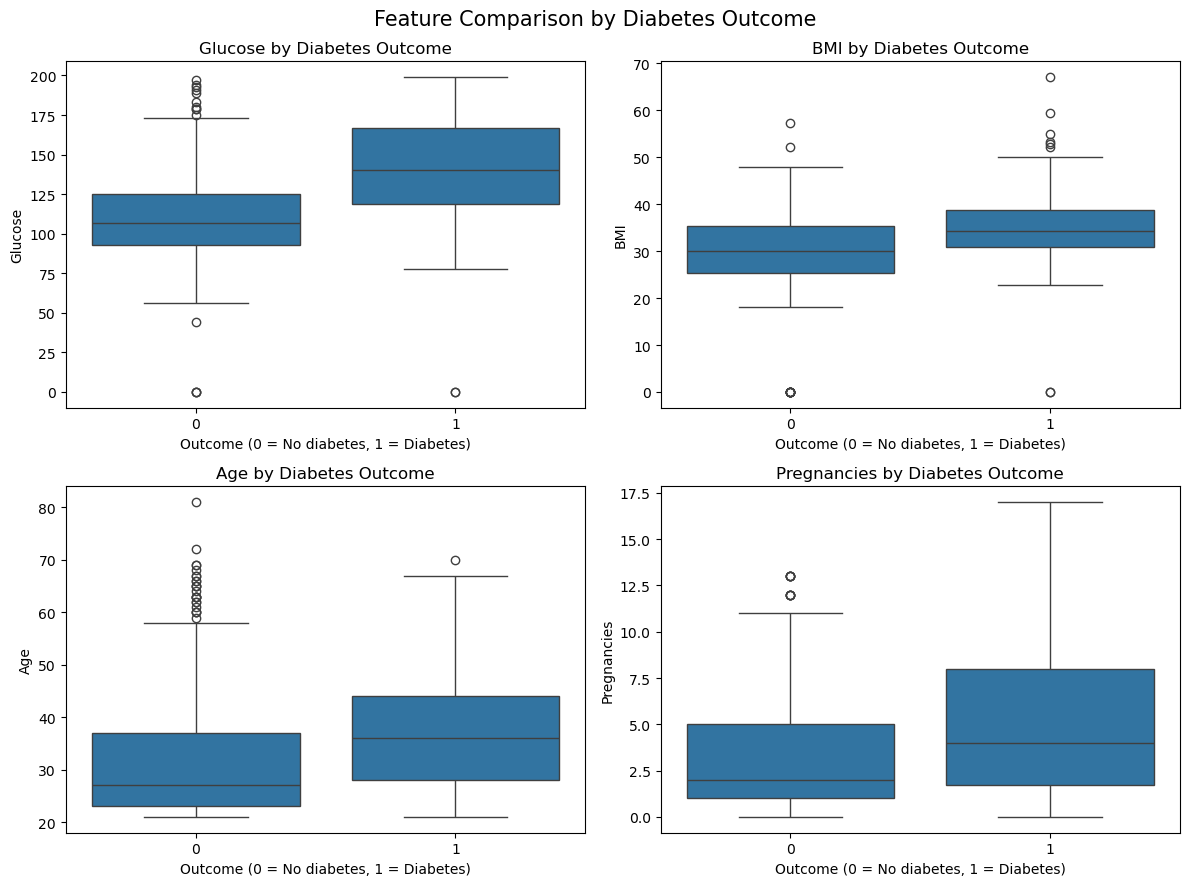

In [10]:

# Compare important features by diabetes outcome
features_to_compare = ["Glucose", "BMI", "Age", "Pregnancies"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, feature in zip(axes, features_to_compare):
    sns.boxplot(
        data=df,
        x="Outcome",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Diabetes Outcome")
    ax.set_xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")

plt.suptitle("Feature Comparison by Diabetes Outcome", fontsize=15)
plt.tight_layout()

plt.savefig(
    "../reports/figures/feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

# Create a separate copy for modeling
df_clean = df.copy()

# Features where zero is treated as an invalid/missing measurement
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zeros with NaN in the copied dataset
df_clean[invalid_zero_columns] = (
    df_clean[invalid_zero_columns].replace(0, np.nan)
)

# Check the results
print("Missing values after zero handling:")
display(df_clean.isnull().sum())

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)


Missing values after zero handling:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Original shape: (768, 9)
Cleaned shape: (768, 9)


In [12]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (614, 8)
Testing features: (154, 8)

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing target distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


In [13]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Columns where zero represents an invalid measurement
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Make copies so the original split remains unchanged
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Replace invalid zeros with missing values
X_train_clean[zero_columns] = X_train_clean[zero_columns].replace(0, np.nan)
X_test_clean[zero_columns] = X_test_clean[zero_columns].replace(0, np.nan)

# Learn median values from training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_clean),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test_clean),
    columns=X_test.columns,
    index=X_test.index
)

print("Training data shape:", X_train_imputed.shape)
print("Testing data shape:", X_test_imputed.shape)
print("Missing values in training data:", X_train_imputed.isnull().sum().sum())
print("Missing values in testing data:", X_test_imputed.isnull().sum().sum())


Training data shape: (614, 8)
Testing data shape: (154, 8)
Missing values in training data: 0
Missing values in testing data: 0


In [14]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train the first model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_imputed, y_train)

# Make predictions on unseen test data
y_pred = lr_model.predict(X_test_imputed)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7013

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154


Confusion Matrix:
[[81 19]
 [27 27]]


In [15]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Build a complete preprocessing and modelling pipeline
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train using the original split
lr_pipeline.fit(X_train_clean, y_train)

# Evaluate on the untouched test set
y_pred_scaled = lr_pipeline.predict(X_test_clean)

print("Accuracy:", round(accuracy_score(y_test, y_pred_scaled), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_scaled))


Accuracy: 0.7338

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154


Confusion Matrix:
[[75 25]
 [16 38]]


In [16]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_imputed, y_train)

y_pred_rf = rf_model.predict(X_test_imputed)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Accuracy: 0.7403

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.83      0.81       100
           1       0.65      0.57      0.61        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.71       154
weighted avg       0.73      0.74      0.74       154


Confusion Matrix:
[[83 17]
 [23 31]]


In [17]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [18]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_imputed, y_train)

y_pred_xgb = xgb_model.predict(X_test_imputed)

print("XGBoost Accuracy:",
      round(accuracy_score(y_test, y_pred_xgb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


XGBoost Accuracy: 0.7792

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.86      0.83       100
           1       0.71      0.63      0.67        54

    accuracy                           0.78       154
   macro avg       0.76      0.74      0.75       154
weighted avg       0.78      0.78      0.78       154


Confusion Matrix:
[[86 14]
 [20 34]]


In [19]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
import pandas as pd

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200, class_weight="balanced", random_state=42
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=42))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(class_weight="balanced", probability=True, random_state=42))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42
        ))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train_clean,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(3))


,Model,Accuracy,Recall,F1,ROC_AUC
0,Logistic Regression,0.762,0.701,0.672,0.844
1,SVM,0.761,0.762,0.690,0.837
2,Random Forest,0.769,0.593,0.642,0.822
3,Gradient Boosting,0.756,0.598,0.631,0.819
4,XGBoost,0.756,0.593,0.628,0.817
5,KNN,0.730,0.565,0.594,0.784


In [20]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train_clean, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best mean CV ROC-AUC:", round(grid_search.best_score_, 4))


Best parameters: {'model__C': 0.1, 'model__solver': 'lbfgs'}
Best mean CV ROC-AUC: 0.845


In [21]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test_imputed)
y_prob = best_model.predict_proba(X_test_imputed)[:, 1]

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Test Accuracy: 0.7078
Test ROC-AUC: 0.8104

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.73      0.76       100
           1       0.57      0.67      0.62        54

    accuracy                           0.71       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.71      0.71       154


Confusion Matrix:
[[73 27]
 [18 36]]


In [24]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

# Use the existing test set for each model
predictions = {
    "Logistic Regression": models["Logistic Regression"].fit(
        X_train, y_train
    ).predict(X_test),
    "SVM": models["SVM"].fit(
        X_train, y_train
    ).predict(X_test),
    "Random Forest": models["Random Forest"].fit(
        X_train, y_train
    ).predict(X_test),
    "Gradient Boosting": models["Gradient Boosting"].fit(
        X_train, y_train
    ).predict(X_test),
    "XGBoost": models["XGBoost"].fit(
        X_train, y_train
    ).predict(X_test),
    "Tuned Logistic Regression": grid_search.best_estimator_.predict(
        X_test_clean
    )
}

test_results = []

for name, pred in predictions.items():
    test_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1 Score": round(f1_score(y_test, pred), 3)
    })

results_df = pd.DataFrame(test_results)
results_df.sort_values("Recall", ascending=False)

,Model,Accuracy,Recall,F1 Score
1,SVM,0.727,0.722,0.650
0,Logistic Regression,0.734,0.704,0.650
5,Tuned Logistic Regression,0.708,0.667,0.615
4,XGBoost,0.779,0.630,0.667
2,Random Forest,0.740,0.574,0.608
3,Gradient Boosting,0.760,0.574,0.626


In [25]:
import joblib
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    grid_search.best_estimator_,
    "../models/diabetes_logistic_regression.pkl"
)

print("Model saved:", Path(
    "../models/diabetes_logistic_regression.pkl"
).exists())

Model saved: True


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the test set
importance = permutation_importance(
    best_model,
    X_test_clean,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test_clean.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df)

,Feature,Importance,Std
1,Glucose,0.144093,0.032138
5,BMI,0.027056,0.016767
0,Pregnancies,0.022907,0.008230
6,DiabetesPedigreeFunction,0.011537,0.003860
7,Age,0.004685,0.002906
4,Insulin,0.000889,0.000607
3,SkinThickness,0.000259,0.001598
2,BloodPressure,0.000204,0.000605


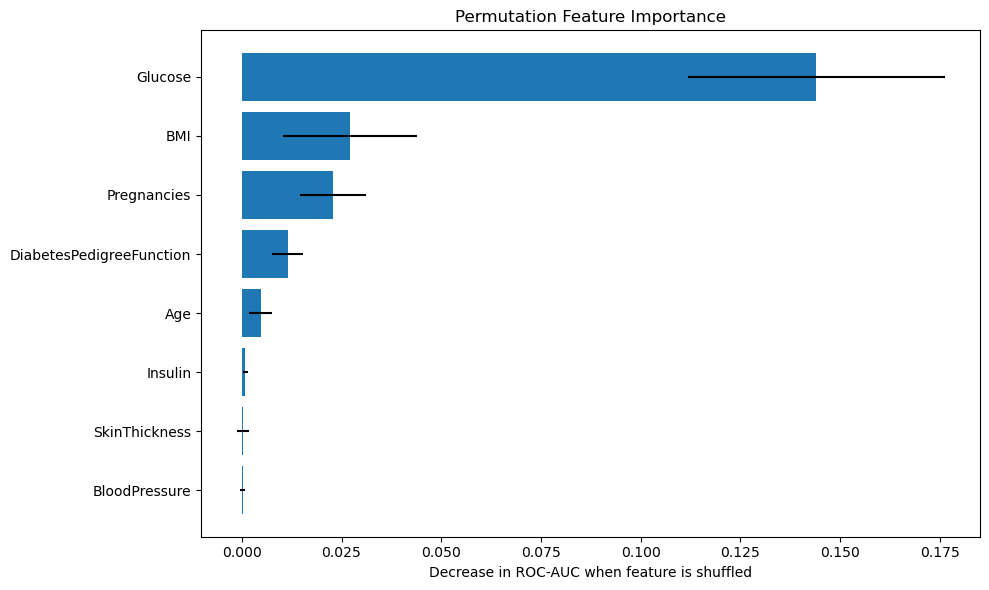

In [27]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "../reports/figures/permutation_importance.png",
    bbox_inches="tight"
)

plt.show()